# 实验 04：保留残差正负号，估计误差并认证剩余量

本实验沿用之前训练完成的同一个 PINN，权重已嵌入笔记，不重新训练。求解对象为 $-u''=2$、区间 $[0,1]$、零边界。网络输出保持不变；辅助误差估计只用于认证原输出。

## 文献与本实验的关系

1. Cao, O'Leary-Roseberry, Jha, Oden, Ghattas, *Residual-based error correction for neural operator accelerated infinite-dimensional Bayesian inverse problems*, JCP, 2023. https://arxiv.org/abs/2210.03008 。文中通过基于残差的线性变分问题修正神经算子预测，在相应假设下可有二次误差下降。本文借鉴“求一个误差修正问题”的思路，改为认证固定近似解，不是原论文完整复现。
2. Ernst, Rekatsinas, Urban, *A posteriori certification of PDE approximations with particular application to neural networks*, 2025 初稿，2026-08-28 v6. https://arxiv.org/abs/2502.20336 。研究自然范数下通过残差的 Riesz 表示和区域延拓/限制构造上下界；不是直接给当前最大误差的倍数。
3. Fanaskov, Yu, Rudikov, Oseledets, *Astral: training physics-informed neural networks with error majorants*, 2024 初稿，2026 v2，ICLR 2026 AI&PDE workshop. https://arxiv.org/abs/2406.02645 。用辅助场与函数型误差上界训练，实验报告部分能量误差界较紧；不能与当前最大误差倍数直接横向比较。原文也指出积分数值误差可能破坏上界。
4. Führer, Rojas, *A posteriori analysis of neural network approximations*, 2025 preprint. https://arxiv.org/abs/2507.06017 。将可计算的离散残差投影与需另行控制的剩余项分开，适合学习“算得出的部分＋剩余认证”的结构；其理论范数和常数需单独核对。

额外线索：Anwer et al., *Pointwise Error Estimates for Numerical Physics-Informed Neural Networks*, 2026 preprint, https://arxiv.org/abs/2607.03431 。本次只核对了检索返回的原始摘要，全文获取失败。摘要描述兼容有限元重构、离散伴随 Green 表示及从离散目标到连续解的误差转移；尚未完整复现或核查其定理，不据此声称其结论直接适用于当前光滑 PINN。

下文是当前一维线性问题的经典误差方程与比较原理实现，不宣称新理论贡献。所有保证均先在精确实数算术下陈述；代码为普通 float64，尚无向外舍入或求值误差包络。


In [1]:
import json
import time
import numpy as np
import matplotlib.pyplot as plt
weights = json.loads('{"hidden.weight": [[-0.11655703152469872], [-0.2018080591461949], [0.4583162375718069], [0.20026538914519], [0.7756982500749172], [0.6742251714702365], [-0.23886249891440564], [-0.015972329244446814], [0.15495054929215127], [0.40925202029437746], [-1.064355372348248], [-0.7289114586982176], [-0.432126169361768], [-0.9753575808091411], [-0.5797251397767852], [0.413016653300717]], "hidden.bias": [-0.7964742364253344, 1.04609497315135, -0.8985656108997572, 0.8314479318949629, 0.658896077752849, 0.551308758724174, 0.4390765902847739, -0.5133502497582167, 0.6643002332227377, 0.629175889664992, 0.706121480684401, 0.8927699184593991, -0.9348675289884024, 0.9050058336419343, 0.2240944649313563, -0.9513698462038765], "output.weight": [[-0.06861713988529242, 0.23739684108928555, -0.15106505846447962, -0.07831394517377012, -0.03707287650474282, -0.09767832746735168, 0.18557952082528661, -0.2039472044479674, 0.09590278924364797, 0.3183226149593691, 0.04467755812652954, -0.1016417179081969, -0.26398918915600494, -0.09612154461026647, 0.024498051289461024, -0.16009472903431574]], "output.bias": [0.17573307305441363]}')
w = np.array(weights['hidden.weight']).flatten()
b = np.array(weights['hidden.bias'])
a = np.array(weights['output.weight']).flatten()
c = weights['output.bias'][0]

def fields(x):
    x = np.asarray(x)
    t = np.tanh(x[..., None]*w+b)
    n = c + t@a
    n1 = ((1-t*t)*(a*w)).sum(axis=-1)
    n2 = ((-2*t+2*t**3)*(a*w**2)).sum(axis=-1)
    n3 = ((-2+8*t*t-6*t**4)*(a*w**3)).sum(axis=-1)
    q=x*(1-x)
    qp=1-2*x
    v=q*n
    v2=q*n2+2*qp*n1-2*n
    v3=q*n3+3*qp*n2-6*n1
    return v, -v2-2, -v3

global_M = 6*np.sum(abs(a*w)) + 6*np.sum(abs(a)*w**2) + 0.5*np.sum(abs(a)*abs(w)**3)
x_error=np.linspace(0,1,10001)
v_error, _, _=fields(x_error)
reference_error=np.max(abs(v_error-x_error*(1-x_error)))
assert np.isclose(reference_error, 2.6974090221676406e-5, atol=1e-13, rtol=0)
print('Reused weights; no training was performed.')
print(f'Reference-grid error: {reference_error:.10e}')
print(f'Original global derivative bound M: {global_M:.8f}')


Reused weights; no training was performed.
Reference-grid error: 2.6974090222e-05
Original global derivative bound M: 7.93823056


## 1. 在小区间上保留导数的符号和输入范围

每个神经元在区间 $I=[l,u]$ 的输入范围可从已知权重直接计算。令 $t=\tanh(wx+b)$，则

$$\sigma'=1-t^2,\quad \sigma''=-2t+2t^3,\quad \sigma^{(3)}=-2+8t^2-6t^4.$$

这些多项式在闭区间上的极值出现在端点或已知的驻点。计算其范围，再按区间运算传播至 $v^{(3)}=qN^{(3)}+3q'N''-6N'$，即可得到该小区间的 $M_i$。

这一步不靠导数采样来宣称全域保证，也不需要第四阶导数。区间运算可能过宽，但数学上的包含性质成立。


In [2]:
def poly(t, order):
    if order == 1: return 1-t*t
    if order == 2: return -2*t+2*t**3
    return -2+8*t*t-6*t**4

def activation_derivative_range(lo, hi, order):
    left, right = poly(lo,order), poly(hi,order)
    lower, upper = np.minimum(left,right), np.maximum(left,right)
    roots = {1:[0.0], 2:[-1/np.sqrt(3),1/np.sqrt(3)],
             3:[-np.sqrt(2/3),0.0,np.sqrt(2/3)]}[order]
    for z in roots:
        inside=(lo<=z)&(z<=hi)
        value=poly(z,order)
        lower=np.where(inside,np.minimum(lower,value),lower)
        upper=np.where(inside,np.maximum(upper,value),upper)
    return lower, upper

def interval_mul(l1,u1,l2,u2):
    p=np.array([l1*l2,l1*u2,u1*l2,u1*u2])
    return p.min(axis=0),p.max(axis=0)

def local_derivative_bounds(nodes):
    left,right=nodes[:-1],nodes[1:]
    z1=left[:,None]*w+b
    z2=right[:,None]*w+b
    tl=np.tanh(np.minimum(z1,z2))
    tu=np.tanh(np.maximum(z1,z2))
    n_ranges=[]
    for order in [1,2,3]:
        sl,su=activation_derivative_range(tl,tu,order)
        coeff=a*w**order
        n_ranges.append((np.minimum(sl*coeff,su*coeff).sum(axis=1),
                         np.maximum(sl*coeff,su*coeff).sum(axis=1)))
    ql=np.minimum(left*(1-left),right*(1-right))
    qu=np.maximum(left*(1-left),right*(1-right))
    qu=np.where((left<=0.5)&(right>=0.5),0.25,qu)
    qpl,qpu=1-2*right,1-2*left
    t3=interval_mul(ql,qu,*n_ranges[2])
    t2=interval_mul(qpl,qpu,*n_ranges[1])
    lower=t3[0]+3*t2[0]-6*n_ranges[0][1]
    upper=t3[1]+3*t2[1]-6*n_ranges[0][0]
    return np.maximum(abs(lower),abs(upper))


## 2. 空间加权：不同位置的残差对解误差的影响不同

对于当前零边界问题，有经典 Green 表示：
$$e(x)=\int_0^1G(x,s)r(s)\,ds,\qquad G(x,s)=\min(x,s)(1-\max(x,s))\geq0.$$

因此，如果每个小区间上 $|r|\leq\varepsilon_i$，把这些上界拼成分段常数函数 $\bar\varepsilon(s)$，就有
$$|e(x)|\leq B(x)=\int_0^1G(x,s)\bar\varepsilon(s)\,ds.$$

只需求 $-B''=\bar\varepsilon$、$B(0)=B(1)=0$。因为右端分段常数，$B$ 是分段二次函数，其每段极值可直接求出，无需对 Green 积分做未经控制的数值求积。每段残差界取
$$\varepsilon_i=\max(|r(x_i)|,|r(x_{i+1})|)+M_i h_i/2.$$

边界附近的 Green 权重较小。统一使用 $\varepsilon/8$ 相当于把整个区域都替换成最坏残差，丢失了这种空间信息。

Green 表示的一般原理参考：https://www.math.cmu.edu/~gautam/c/2026-632/notes/greens-functions.html


In [3]:
def envelope_maximum(nodes, eps):
    h=np.diff(nodes)
    mid=(nodes[:-1]+nodes[1:])/2
    slope=np.sum(eps*h*(1-mid))
    value=0.0
    maximum=0.0
    trace=[0.0]
    for width, forcing in zip(h,eps):
        t=np.clip(slope/forcing,0,width) if forcing>0 else (width if slope>0 else 0)
        maximum=max(maximum, value+slope*t-0.5*forcing*t*t)
        value += slope*width-0.5*forcing*width*width
        slope -= forcing*width
        trace.append(value)
    assert abs(value)<1e-12
    return maximum,np.array(trace)

nodes=np.linspace(0,1,1001)
h=np.diff(nodes)
_,r_nodes,_=fields(nodes)
local_M=local_derivative_bounds(nodes)
_,_,rp_mid=fields((nodes[:-1]+nodes[1:])/2)
assert np.all(abs(rp_mid)<=local_M+1e-12)
endpoint_max=np.maximum(abs(r_nodes[:-1]),abs(r_nodes[1:]))
eps_global=endpoint_max+global_M*h/2
eps_local=endpoint_max+local_M*h/2

green_global,trace_global=envelope_maximum(nodes,eps_global)
green_local,trace_local=envelope_maximum(nodes,eps_local)
methods=[
    ('Global M + uniform residual', np.max(eps_global)/8),
    ('Local M + uniform residual', np.max(eps_local)/8),
    ('Global M + Green envelope', green_global),
    ('Local M + Green envelope', green_local),
]
print('All methods: same fixed weights and 1001 residual samples')
print('method                              bound          bound / reference')
for name,eta in methods:
    assert eta>=reference_error-1e-12
    print(f'{name:34s} {eta:13.7e} {eta/reference_error:18.4f}')
print(f'Maximum of local derivative bounds: {local_M.max():.8f}')
_,_,rp_dense=fields(x_error)
print(f'Derivative maximum observed on dense grid: {np.max(abs(rp_dense)):.8f}')
print(f'Global M / max local bound: {global_M/local_M.max():.3f}')
print(f'Max sampled residual at x={nodes[np.argmax(abs(r_nodes))]:.5f}')

# 与旧实验交叉检查。解析极值位置可能不在网格，下面仅为实现检查。
assert np.isclose(methods[0][1],0.0014159097093060303,atol=1e-12,rtol=0)
assert green_local<=methods[1][1]+1e-12
assert green_local<=green_global+1e-12
assert methods[1][1]<=methods[0][1]+1e-12

# 校验分段包络积分：常数源项 2 应得到 B=x(1-x)，最大值 1/4。
test_nodes=np.array([0.0,0.1,0.3,0.9,1.0])
test_max,test_trace=envelope_maximum(test_nodes,np.full(4,2.0))
assert np.isclose(test_max,0.25,atol=1e-14)
assert np.allclose(test_trace,test_nodes*(1-test_nodes),atol=1e-14)
# 在每个区间额外检查 11 个点，发现区间实现错误；采样不替代理论证明。
test_x=nodes[:-1,None]+h[:,None]*np.linspace(0,1,11)[None,:]
_,test_r,test_rp=fields(test_x)
assert np.all(abs(test_rp)<=local_M[:,None]+1e-12)
assert np.all(abs(test_r)<=eps_local[:,None]+1e-12)
print('Checks passed: old baseline, analytic envelope example, interval bounds at independent points.')


All methods: same fixed weights and 1001 residual samples
method                              bound          bound / reference
Global M + uniform residual        1.4159097e-03            52.4915
Local M + uniform residual         9.2800690e-04            34.4036
Global M + Green envelope          6.5330548e-04            24.2197
Local M + Green envelope           1.5831685e-04             5.8692
Maximum of local derivative bounds: 0.13178559
Derivative maximum observed on dense grid: 0.13093384
Global M / max local bound: 60.236
Max sampled residual at x=1.00000
Checks passed: old baseline, analytic envelope example, interval bounds at independent points.


## 新方法：把误差分成“已估计部分＋待认证剩余”

先前使用 $|r|$ 构造包络，丢失了不同位置残差的正负抵消。现在在每段取带符号的常数
$$m_i=\frac{r(x_i)+r(x_{i+1})}{2},\qquad \delta_i=M_i h_i/2.$$

由局部 Lipschitz 界，对该段任意 $s$，分别从两端写不等式并相加，可得 $|r(s)-m_i|\leq\delta_i$。

用已知 $m$ 求辅助问题 $-z''=m$，$z(0)=z(1)=0$。这里没有使用精确解。因为 $m$ 分段常数，可以直接积分得到分段二次的 $z$，并在每段端点及驻点求出连续最大绝对值 $Z=\|z\|_\infty$。

真实误差 $e=v-u^*$ 满足 $-e''=r$。因此 $d=e-z$ 满足 $-d''=r-m$。设 $-D''(x)=\delta(x)$，$D(0)=D(1)=0$，由比较原理 $|d(x)|\leq D(x)$。令 $D_{\max}=\max_xD(x)$，得到：

$$\boxed{\max(0,Z-D_{\max})\leq\|e\|_\infty\leq Z+D_{\max}.}$$

注意：$Z$ 只是误差估计；加上经过控制的 $D_{\max}$ 才得到上界。若要修改网络输出，可用 $v-z$，但本实验保持 $v$ 不变，只认证原始输出。


In [4]:
def signed_poisson(nodes, source):
    h=np.diff(nodes)
    mid=(nodes[:-1]+nodes[1:])/2
    slope=np.sum(source*h*(1-mid))
    value=0.0
    max_abs=0.0
    trace=[0.0]
    for width,f in zip(h,source):
        candidates=[0.0,width]
        if f != 0:
            t=slope/f
            if 0<t<width:candidates.append(t)
        for t in candidates:
            max_abs=max(max_abs,abs(value+slope*t-0.5*f*t*t))
        value+=slope*width-0.5*f*width*width
        slope-=f*width
        trace.append(value)
    assert abs(value)<1e-12
    return max_abs,np.array(trace)

# 检查解算器的正负号和连续极值计算。
test_nodes=np.array([0.,0.2,0.7,1.])
for f in [2.,-2.]:
    zmax,zt=signed_poisson(test_nodes,np.full(3,f))
    assert np.isclose(zmax,0.25,atol=1e-14)
    assert np.allclose(zt,(f/2)*test_nodes*(1-test_nodes),atol=1e-14)

signed_results=[]
for intervals in [100,1000,10000]:
    ns=np.linspace(0,1,intervals+1)
    widths=np.diff(ns)
    _,rs,_=fields(ns)
    ms=(rs[:-1]+rs[1:])/2
    mi=local_derivative_bounds(ns)
    delta=mi*widths/2
    Z,z_trace=signed_poisson(ns,ms)
    D,d_trace=envelope_maximum(ns,delta)
    lower=max(0.,Z-D)
    upper=Z+D
    assert lower<=reference_error+1e-12
    assert upper>=reference_error-1e-12
    # 节点处对照只用于实现检查，精确解不参与 Z、D 的计算。
    vs,_,_=fields(ns)
    es=vs-ns*(1-ns)
    assert np.all(abs(es-z_trace)<=d_trace+1e-12)
    if intervals==1000:
        # 额外的区间内部实现检查，不能替代理论证明。
        tx=ns[:-1,None]+widths[:,None]*np.linspace(0,1,11)
        _,tr,_=fields(tx)
        assert np.all(abs(tr-ms[:,None])<=delta[:,None]+1e-12)
        plot_data=(ns,z_trace,d_trace,es)
    signed_results.append(dict(intervals=intervals,Z=Z,D=D,lower=lower,
                               upper=upper,ratio=upper/reference_error))

print('Same original PINN; signed residual correction used only for certification')
print('intervals       lower bound        upper bound      upper / reference')
for row in signed_results:
    print(f'{row["intervals"]:9d} {row["lower"]:17.9e} {row["upper"]:17.9e} {row["ratio"]:18.6f}')
row=signed_results[1]
print(f'At 1001 residual check points: estimated error norm Z = {row["Z"]:.10e}')
print(f'Remainder bound D_max = {row["D"]:.10e}')
print(f'Previous unsigned local Green bound: {green_local:.10e}')
print('Checks passed: constant-source solver tests, interval interior checks, independent exact-solution comparisons.')


Same original PINN; signed residual correction used only for certification
intervals       lower bound        upper bound      upper / reference
      100   1.157639355e-05   4.206597182e-05           1.559495
     1000   2.604381286e-05   2.790131208e-05           1.034375
    10000   2.688705838e-05   2.706109458e-05           1.003225
At 1001 residual check points: estimated error norm Z = 2.6972562470e-05
Remainder bound D_max = 9.2874960589e-07
Previous unsigned local Green bound: 1.5831684614e-04
Checks passed: constant-source solver tests, interval interior checks, independent exact-solution comparisons.


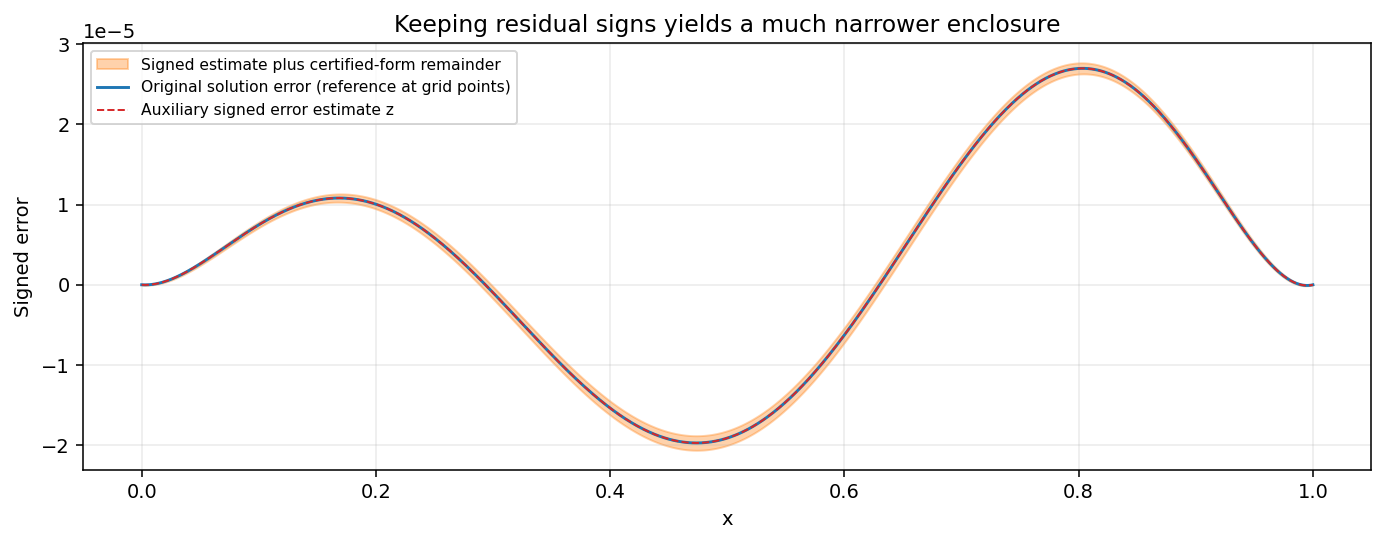

In [5]:
px,pz,pd,pe=plot_data
fig,ax=plt.subplots(figsize=(10,4))
ax.fill_between(px,pz-pd,pz+pd,color='tab:orange',alpha=0.35,
                label='Signed estimate plus certified-form remainder')
ax.plot(px,pe,color='tab:blue',label='Original solution error (reference at grid points)')
ax.plot(px,pz,'--',color='tab:red',linewidth=1,label='Auxiliary signed error estimate z')
ax.set(xlabel='x',ylabel='Signed error',title='Keeping residual signs yields a much narrower enclosure')
ax.grid(alpha=0.25)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


## 解释与边界

- 误差上界与下界均根据残差和固定网络计算，不以参考解误差来拟合或校准。
- 比值的分母仍为密集网格参考误差。之前的二阶插值误差论证可用于包住连续误差遗漏量；本代码没有实现浮点舍入包络。
- 该方法在一维线性问题上很便宜，但计算辅助误差方程本质上需要施加原算子的逆。在更高维或更复杂 PDE 中，成本可能接近重新求解，必须与传统求解器比较。
- 结果来自同一简单算例和一个训练种子，不代表文献原方法的完整复现，也不能据此宣称普遍优于其他认证方法。
- 下一步应比较多种源项、网络训练程度、随机种子、网格分辨率下的有效性、紧致程度与计算成本，并完成数值舍入认证。
